In [1]:
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
import csv

In [2]:
df=gpd.read_file("../../Speculation-Map/Data/divisions-administratives-v2r1-municipis-1000000-20250730.json")

In [3]:
df

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5..."
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((1.61829 41.76885, 1.61278 41.7..."
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((2.28512 41.51534, 2.28501 41.5..."
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((2.09411 42.14192, 2.09031 42.1..."
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((2.24126 41.70273, 2.24178 41.7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,439039,Camarles,Camarles,30.0157,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((0.6437 40.8212, 0.64239 40.821..."
943,439044,l'Aldea,l'Aldea,30.4743,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((0.60964 40.80699, 0.60855 40.8..."
944,439057,Salou,Salou,15.1248,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,43,Tarragona,Tarragona,"MULTIPOLYGON (((1.14208 41.09693, 1.13671 41.0..."
945,439060,l'Ampolla,l'Ampolla,35.6196,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((0.69184 40.85044, 0.69102 40.8..."


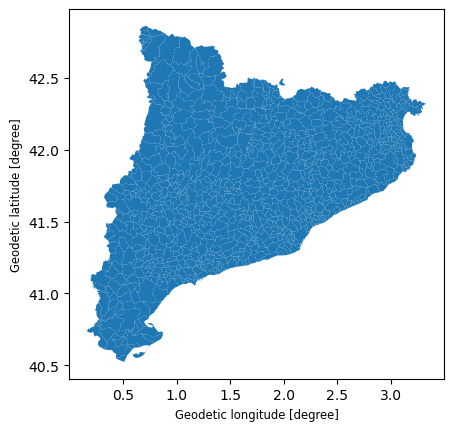

In [4]:
df.plot()
plt.show()

In [5]:
dh=gpd.read_file("../../Speculation-Map/Data/Thomas/Impost_sobre_els_habitatges_buits_(IHB)_per_municipi_i_exercici_de_meritació_20261118.csv")

In [6]:
dh['CODIMUNI'] = dh['Codi']
dh

,Any,Codi,Municipi,Exempt,Habitatges,Tenidor,Superfície útil,CODIMUNI
0,2018,080018,Abrera,No,3,2,"474,10",080018
1,2018,080039,Alella,No,2,2,"629,00",080039
2,2018,080057,"Ametlla del Vallès, l'",Sí,35,5,"6.354,78",080057
3,2018,080060,Arenys de Mar,No,22,5,"1.637,90",080060
4,2018,080076,Arenys de Munt,No,20,6,"2.914,77",080076
...,...,...,...,...,...,...,...,...
6038,2025,439044,"Aldea, l'",No,61,3,"2.649,71",439044
6039,2025,439057,Salou,No,14,11,"867,23",439057
6040,2025,439057,Salou,Sí,413,6,"21.886,53",439057
6041,2025,439076,"Canonja, la",No,2,2,"100,05",439076


In [7]:
df = df.merge(dh, on='CODIMUNI', how='left' )

In [8]:
df

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,...,NOMPROV,CAPPROV,geometry,Any,Codi,Municipi,Exempt,Habitatges,Tenidor,Superfície útil
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2018,080018,Abrera,No,3,2,"474,10"
1,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2019,080018,Abrera,No,3,2,"569,80"
2,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2020,080018,Abrera,No,4,3,"537,50"
3,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2020,080018,Abrera,Sí,1,1,"90,70"
4,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2021,080018,Abrera,No,3,2,"739,00"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5228,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2023,439076,"Canonja, la",No,4,2,"223,01"
5229,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2024,439076,"Canonja, la",No,3,3,"210,30"
5230,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2024,439076,"Canonja, la",Sí,13,3,"1.401,66"
5231,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2025,439076,"Canonja, la",No,2,2,"100,05"


In [9]:
totqls = df.groupby("CODIMUNI").agg(
    Hab=("Habitatges","sum")).reset_index()

In [10]:
totqls

,CODIMUNI,Hab
0,080018,33413142
1,080023,
2,080039,21332
3,080044,
4,080057,3531384644
...,...,...
942,439039,182928121197141
943,439044,50546261942238217111111561
944,439057,9339950431774153941939422304201342714413
945,439060,15811320262570


In [11]:
df_final = df.merge(totqls, on='CODIMUNI', how = 'left', suffixes=("", "_total"))

In [12]:
df_final

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,...,CAPPROV,geometry,Any,Codi,Municipi,Exempt,Habitatges,Tenidor,Superfície útil,Hab
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2018,080018,Abrera,No,3,2,"474,10",33413142
1,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2019,080018,Abrera,No,3,2,"569,80",33413142
2,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2020,080018,Abrera,No,4,3,"537,50",33413142
3,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2020,080018,Abrera,Sí,1,1,"90,70",33413142
4,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,Barcelona,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",2021,080018,Abrera,No,3,2,"739,00",33413142
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5228,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2023,439076,"Canonja, la",No,4,2,"223,01",11268173334313214
5229,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2024,439076,"Canonja, la",No,3,3,"210,30",11268173334313214
5230,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2024,439076,"Canonja, la",Sí,13,3,"1.401,66",11268173334313214
5231,439076,la Canonja,la Canonja,7.3528,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,...,Tarragona,"MULTIPOLYGON (((1.1711 41.1384, 1.16506 41.138...",2025,439076,"Canonja, la",No,2,2,"100,05",11268173334313214


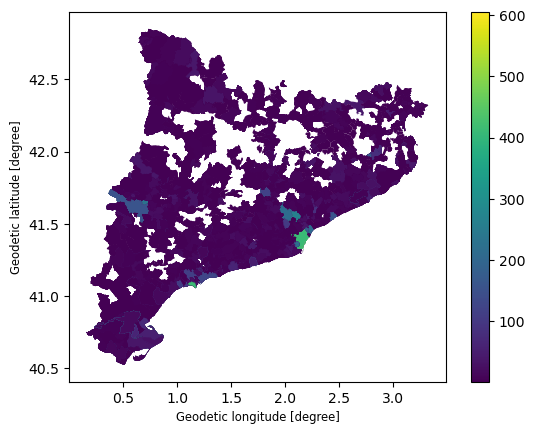

In [13]:
df_final['Habitatges']=pd.DataFrame.astype(df_final['Habitatges'],dtype='float')
df_final.plot(column='Habitatges',legend=True)
plt.show()

In [14]:
Habitatges=df_final['Habitatges']

In [15]:
df_final['Habitatges']=pd.DataFrame.astype(df_final['Habitatges'],dtype='float')

In [16]:
Hab=df_final['Hab']

In [17]:
idb=Hab==''

In [18]:
sum(idb)

193

In [19]:
Hab[idb]='0'

In [20]:
sum(Hab=='0')

193

In [21]:
df_final['Hab']=Hab

In [22]:
df_final['Hab']=pd.DataFrame.astype(df_final['Hab'],dtype='float')

In [23]:
type(df_final['Hab'][3])

numpy.float64

In [24]:
dg=df["CODIMUNI"]

In [25]:
dg=dg.merge(df_final['Habitatges'],on='Codimuni',how='left')

AttributeError: 'Series' object has no attribute 'merge'

In [27]:
df_final['Habitatges']['Hab']

KeyError: 'Hab'